##### Ironhack - AI Integration & Consulting

# Part 2: Unguided Exercise - Customer Churn Prediction

Goal: Predict customer churn for a telecommunications company. 



### Step 1: Load and Explore the Data

- Download the Telco Customer Churn dataset
- Load it into a pandas DataFrame
- Explore the dataset: shape, columns, data types, missing values
- Check the target distribution (how many churned vs. didn't churn)
- Visualize some key features

In [7]:
# Download the Telco Customer Churn dataset
# Load it into a pandas DataFrame
# Checking first few rows to ensure it loaded correctly

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, confusion_matrix, classification_report
from sklearn.preprocessing import StandardScaler

file_path = r"C:\Users\antun\ai-project\W1\Day-3\lab-sklearn-model-training\WA_Fn-UseC_-Telco-Customer-Churn.csv.xls"

telco_df = pd.read_csv(file_path)

print("\nLoading Telco dataset...")

print("\nFirst few rows of the dataset:")
print(telco_df.head())


Loading Telco dataset...

First few rows of the dataset:
   customerID  gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  7590-VHVEG  Female              0     Yes         No       1           No   
1  5575-GNVDE    Male              0      No         No      34          Yes   
2  3668-QPYBK    Male              0      No         No       2          Yes   
3  7795-CFOCW    Male              0      No         No      45           No   
4  9237-HQITU  Female              0      No         No       2          Yes   

      MultipleLines InternetService OnlineSecurity  ... DeviceProtection  \
0  No phone service             DSL             No  ...               No   
1                No             DSL            Yes  ...              Yes   
2                No             DSL            Yes  ...               No   
3  No phone service             DSL            Yes  ...              Yes   
4                No     Fiber optic             No  ...               No   

  Te

In [8]:
# Explore the dataset: shape, columns, data types, missing values
print("Shape:", telco_df.shape) # Here I get number of rows (cusomers) and columns (attributes) in the dataset
print("\nColumns:")
print(telco_df.columns.tolist())

print("\nData types and non-null counts:") # Print the data types of each column and the number of non-null values
telco_df.info()

print("\nBasic statistics:")
print(telco_df.describe(include="all").T) # Calculate basic statistics for each column, including count, mean, std (standard deviation), min, max, and percentiles

Shape: (7043, 21)

Columns:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']

Data types and non-null counts:
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9

In [9]:
# Check the target distribution (how many churned vs. didn't churn)
print(telco_df["Churn"].value_counts()) # Number of customers who stayed and the number who churned.
print(telco_df["Churn"].value_counts(normalize=True)) # Proportion of customers who stayed and the proportion who churned.

# Output here shows considerably more customers did not churn than churned,

Churn
No     5174
Yes    1869
Name: count, dtype: int64
Churn
No     0.73463
Yes    0.26537
Name: proportion, dtype: float64


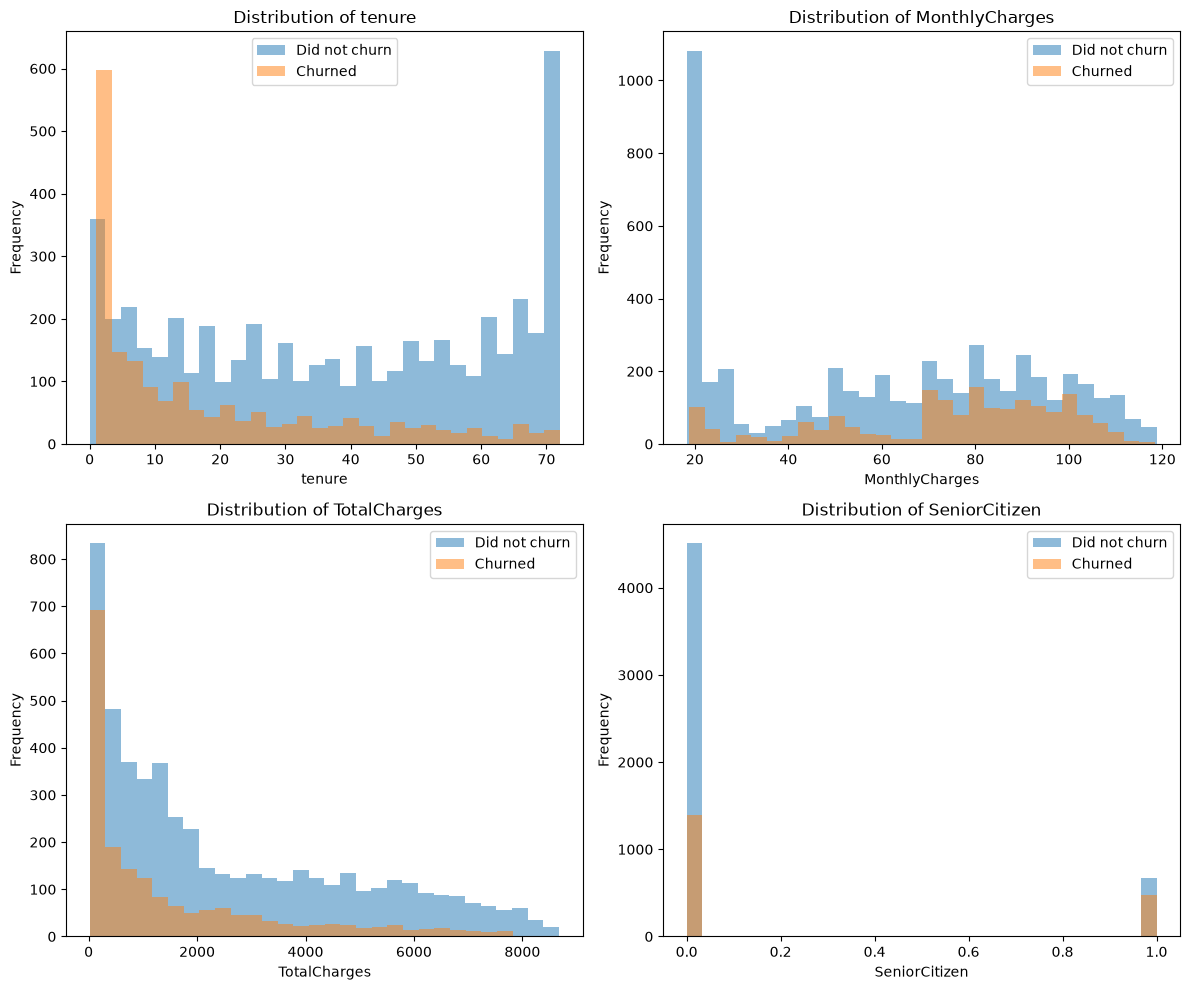

In [10]:
# Visualize some key features
# Convert TotalCharges from text to numbers

telco_df["TotalCharges"] = pd.to_numeric(
    telco_df["TotalCharges"],
    errors="coerce"
)

key_features = [
    "tenure",
    "MonthlyCharges",
    "TotalCharges",
    "SeniorCitizen"
]

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.ravel()

for idx, feature in enumerate(key_features):
    axes[idx].hist(
        telco_df[telco_df["Churn"] == "No"][feature].dropna(),
        alpha=0.5,
        label="Did not churn",
        bins=30
    )

    axes[idx].hist(
        telco_df[telco_df["Churn"] == "Yes"][feature].dropna(),
        alpha=0.5,
        label="Churned",
        bins=30
    )

    axes[idx].set_xlabel(feature)
    axes[idx].set_ylabel("Frequency")
    axes[idx].set_title(f"Distribution of {feature}")
    axes[idx].legend()

plt.tight_layout()
plt.show()

### Step 2: Data Preprocessing

- Handle missing values (if any)
- Convert categorical variables to numeric (use encoding techniques)
- Select relevant features for modeling
- Separate features (X) from target (y)
- Convert target to binary (0/1) if needed

In [11]:
# Handle missing values (if any)
missing = telco_df.isnull().sum()
if missing.sum() == 0:
    print("✓ No missing values found!")
else:
    print(missing[missing > 0])

blank_values = (telco_df == "").sum()
print(blank_values[blank_values > 0])

TotalCharges    11
dtype: int64
Series([], dtype: int64)


In [13]:
#  Convert categorical variables to numeric (use encoding techniques)

# First let's check the variable names in the dataset to identify categorical variables for encoding
print("\nThese are the all columns in the dataset (categorical and numeric):")
print(telco_df.columns.tolist())

print("\nThese are the all columns in the dataset with their data types:")
print(telco_df.dtypes)


These are the all columns in the dataset (categorical and numeric):
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']

These are the all columns in the dataset with their data types:
customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharg

In [14]:

# Keep the target separate and encode it as binary (0 for No, 1 for Yes)
y = telco_df["Churn"].map({"No": 0, "Yes": 1})

# Ignore customerID since it is not a useful feature for prediction
X = telco_df.drop(columns=["customerID", "Churn"], errors="ignore")

# Transform categorical variables into dummy/numeric variables
categorical_columns = X.select_dtypes(
    include=["str", "category"]
).columns

X = pd.get_dummies(
    X,
    columns=categorical_columns,
    drop_first=True,
    dtype=int
)

print("Churn in X:", "Churn" in X.columns)
print("X shape:", X.shape)
print("y shape:", y.shape)

Churn in X: False
X shape: (7043, 30)
y shape: (7043,)


In [15]:
# Checking if columns are now numeric and have been encoded correctly

print("\nThese are the encoded features:")
print(categorical_columns)

print("\nThese are the Churn values:")
print(y.head())

print("\nThese are the value counts for the Churn column:")
print(y.value_counts())


These are the encoded features:
Index(['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines',
       'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
       'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract',
       'PaperlessBilling', 'PaymentMethod'],
      dtype='str')

These are the Churn values:
0    0
1    0
2    1
3    0
4    1
Name: Churn, dtype: int64

These are the value counts for the Churn column:
Churn
0    5174
1    1869
Name: count, dtype: int64


### Step 3: Split the Data

- Split into training (80%) and testing (20%) sets
- Use stratify to maintain class distribution
- Set random_state=42 for reproducibility

In [16]:
from sklearn.model_selection import train_test_split

# Check for unmapped or missing target values
if y.isna().any():
    raise ValueError("Some values in the Churn column were not mapped correctly.")

print(f"Features shape: {X.shape}") # How many rows and feature columns are in X
print(f"Target shape: {y.shape}") # How many Churn columns are in y

# X = Information about the customer
# y = Whether the customer churned or not (target variable)

print(y.value_counts(dropna=False))

# Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("\n" + "=" * 50)
print("DATA SPLIT")
print("=" * 50)
print(f"Training set size: {X_train.shape[0]} samples")
print(f"Test set size: {X_test.shape[0]} samples")
print(f"Training features: {X_train.shape[1]}")
print(f"Test features: {X_test.shape[1]}")

# Verify churn distribution in both sets
print("\nTraining set churn distribution:")
print(y_train.value_counts())
print(f"Did not churn (0): {(y_train == 0).sum()} "
      f"({(y_train == 0).mean() * 100:.1f}%)")
print(f"Churned (1): {(y_train == 1).sum()} "
      f"({(y_train == 1).mean() * 100:.1f}%)")

print("\nTest set churn distribution:")
print(y_test.value_counts())
print(f"Did not churn (0): {(y_test == 0).sum()} "
      f"({(y_test == 0).mean() * 100:.1f}%)")
print(f"Churned (1): {(y_test == 1).sum()} "
      f"({(y_test == 1).mean() * 100:.1f}%)")

Features shape: (7043, 30)
Target shape: (7043,)
Churn
0    5174
1    1869
Name: count, dtype: int64

DATA SPLIT
Training set size: 5634 samples
Test set size: 1409 samples
Training features: 30
Test features: 30

Training set churn distribution:
Churn
0    4139
1    1495
Name: count, dtype: int64
Did not churn (0): 4139 (73.5%)
Churned (1): 1495 (26.5%)

Test set churn distribution:
Churn
0    1035
1     374
Name: count, dtype: int64
Did not churn (0): 1035 (73.5%)
Churned (1): 374 (26.5%)


### Step 4: Train a KNN Model

- Create a KNN classifier
- Start with n_neighbors=5
- Train the model on the training data


In [17]:

print("Checking for NaN values:\n")
print("Missing values in X_train:\n", X_train.isna().sum())
print("\n\nMissing values in y_train:\n", y_train.isna().sum())

train_medians = X_train.median()

X_train = X_train.fillna(train_medians)
X_test = X_test.fillna(train_medians)

print("\n\nChecking for NaN values after training median. This was supposed to replace all NaNs with the median.\n")
print("Missing values in X_train:\n", X_train.isna().sum())
print("\n\nMissing values in y_train:\n", y_train.isna().sum())


Checking for NaN values:

Missing values in X_train:
 SeniorCitizen                            0
tenure                                   0
MonthlyCharges                           0
TotalCharges                             8
gender_Male                              0
Partner_Yes                              0
Dependents_Yes                           0
PhoneService_Yes                         0
MultipleLines_No phone service           0
MultipleLines_Yes                        0
InternetService_Fiber optic              0
InternetService_No                       0
OnlineSecurity_No internet service       0
OnlineSecurity_Yes                       0
OnlineBackup_No internet service         0
OnlineBackup_Yes                         0
DeviceProtection_No internet service     0
DeviceProtection_Yes                     0
TechSupport_No internet service          0
TechSupport_Yes                          0
StreamingTV_No internet service          0
StreamingTV_Yes                          0


In [18]:
# Create KNN classifier
# n_neighbors=5 means the model will look at the 5 nearest neighbors to make a prediction

knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train, y_train)

print("KNN classifier trained successfully!")
print(f"Number of neighbors (k): {knn.n_neighbors}")

KNN classifier trained successfully!
Number of neighbors (k): 5


### Step 5: Make Predictions and Evaluate

- Make predictions on the test set
- Calculate accuracy, precision, and recall
- Create a confusion matrix
- Generate a classification report
- Interpret the results

In [19]:
# Make predictions on the test set

y_train_pred = knn.predict(X_train)
y_test_pred = knn.predict(X_test)
 
print(f"\nTraining predictions: {len(y_train_pred)}")
print(f"Test predictions: {len(y_test_pred)}")


Training predictions: 5634
Test predictions: 1409


In [20]:
# Calculate accuracy, precision, and recall 
# Create a confusion matrix
# Generate a classification report

train_accuracy = accuracy_score(y_train, y_train_pred)
test_accuracy = accuracy_score(y_test, y_test_pred)
test_precision = precision_score(y_test, y_test_pred)
test_recall = recall_score(y_test, y_test_pred)
test_confusion = confusion_matrix(y_test, y_test_pred)
 
print("=== Model Performance ===")
print(f"\nTraining Accuracy: {train_accuracy:.4f} ({train_accuracy*100:.2f}%)")
print(f"Test Accuracy: {test_accuracy:.4f} ({test_accuracy*100:.2f}%)")
print(f"\nTest Precision: {test_precision:.4f}")
print(f"Test Recall: {test_recall:.4f}")
 
print("\n=== Confusion Matrix ===")
print("                Predicted")
print("              Did not Churn  Churned")
print(f"Did not Churn    {test_confusion[0,0]:4d}      {test_confusion[0,1]:4d}")
print(f"      Churned  {test_confusion[1,0]:4d}      {test_confusion[1,1]:4d}")
 
print("\n=== Classification Report ===")
print(classification_report(y_test, y_test_pred, target_names=["Did not churn", "Churned"]))

=== Model Performance ===

Training Accuracy: 0.8277 (82.77%)
Test Accuracy: 0.7658 (76.58%)

Test Precision: 0.5791
Test Recall: 0.4305

=== Confusion Matrix ===
                Predicted
              Did not Churn  Churned
Did not Churn     918       117
      Churned   213       161

=== Classification Report ===
               precision    recall  f1-score   support

Did not churn       0.81      0.89      0.85      1035
      Churned       0.58      0.43      0.49       374

     accuracy                           0.77      1409
    macro avg       0.70      0.66      0.67      1409
 weighted avg       0.75      0.77      0.75      1409



### Interpret the results

Confusion Matrix
- 918 true negatives: These customers did not churn, and the model correctly predicted.
- 117 false positives: These customers did not churn, but the model incorrectly predicted.
- 213 false negatives: These customers did churn, but the model predicted that they would not churn.
- 161 true positivies: These customers churned, and the model correctly predicted that they would churn.

Precision: 0.58 
When the model predicts that a customer will churn, it is correct about 58% of the time.

Recall: 0.43
The model identifies only about 43% of all customers who actually churn.

F1-score: 0.49
The F1-score combines precision and recall. A score of 0.49 shows that the model has limited performance for detecting churners.




### Step 6: Experiment and Improve

- Try different K values (1, 3, 5, 7, 9, 11, 15)
- Compare their performance
- Choose the best K value
- Document your findings


EXPERIMENTING WITH DIFFERENT K VALUES
K= 1: Accuracy=0.7119, Precision=0.4570, Recall=0.4545
K= 3: Accuracy=0.7622, Precision=0.5657, Recall=0.4492
K= 5: Accuracy=0.7658, Precision=0.5791, Recall=0.4305
K= 7: Accuracy=0.7814, Precision=0.6260, Recall=0.4385
K= 9: Accuracy=0.7885, Precision=0.6532, Recall=0.4332
K=11: Accuracy=0.7871, Precision=0.6623, Recall=0.4037

Best K value: 9 (Accuracy: 0.7885)

Saved visualization to 'knn_k_comparison.png'


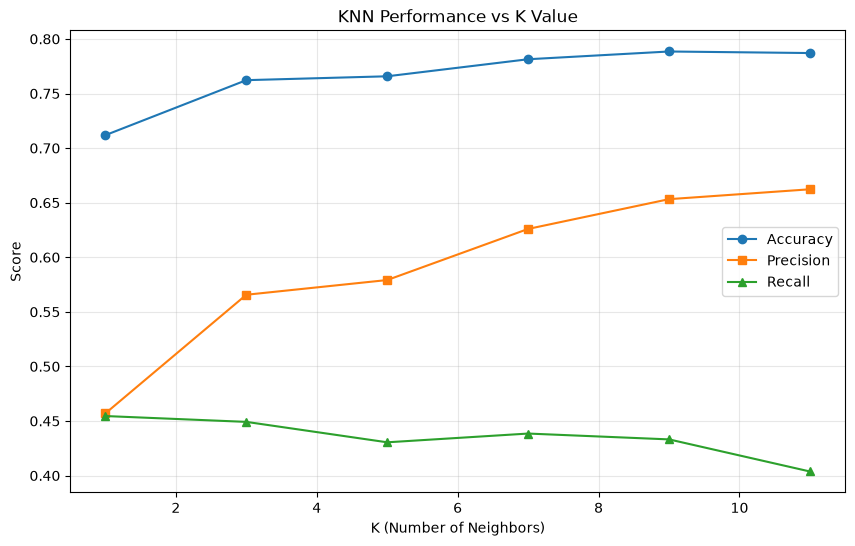

In [21]:
print("\n" + "="*50)
print("EXPERIMENTING WITH DIFFERENT K VALUES")
print("="*50)
 
k_values = [1, 3, 5, 7, 9, 11]
results = []
 
for k in k_values:
    # Create and train model
    knn_temp = KNeighborsClassifier(n_neighbors=k)
    knn_temp.fit(X_train, y_train)
    
    # Make predictions
    y_pred_temp = knn_temp.predict(X_test)
    
    # Calculate accuracy
    acc = accuracy_score(y_test, y_pred_temp)
    prec = precision_score(y_test, y_pred_temp)
    rec = recall_score(y_test, y_pred_temp)
    
    results.append({
        'K': k,
        'Accuracy': acc,
        'Precision': prec,
        'Recall': rec
    })
    
    print(f"K={k:2d}: Accuracy={acc:.4f}, Precision={prec:.4f}, Recall={rec:.4f}")
 
# Find best K
results_df = pd.DataFrame(results)
best_k = results_df.loc[results_df['Accuracy'].idxmax(), 'K']
print(f"\nBest K value: {best_k} (Accuracy: {results_df['Accuracy'].max():.4f})")
 
# Visualize results
plt.figure(figsize=(10, 6))
plt.plot(results_df['K'], results_df['Accuracy'], marker='o', label='Accuracy')
plt.plot(results_df['K'], results_df['Precision'], marker='s', label='Precision')
plt.plot(results_df['K'], results_df['Recall'], marker='^', label='Recall')
plt.xlabel('K (Number of Neighbors)')
plt.ylabel('Score')
plt.title('KNN Performance vs K Value')
plt.legend()
plt.grid(True, alpha=0.3)
plt.savefig('knn_k_comparison.png', dpi=150, bbox_inches='tight')
print("\nSaved visualization to 'knn_k_comparison.png'")
plt.show()

### Step 7: Analysis and Recommendations

- What is the model's accuracy?

The model accuracy is around 77%, this means it predicted the Churn result for approximately 77 out of every 100 test customers.

However, accuracy does not tell the whole story. For customers who actually churned:

Precision: 57.91%
Recall: 43.05%
F1-score: 49%

The model correctly identified only about 43% of the customers who churned, so it missed many potential churners.

- What features seem most important? (You can explore this by looking at feature distributions)

KNN does not provide simple feature importance values like some tree-based models. Some useful features to investigate include: Contract, ternure, MonthlyCharges, TotalCharges, TechSupport, and others. The relationship of these features should be confirmed with further analysis rather than treated as proven causes.

- What would you recommend to the company based on your model?

I think the model is a good termometer to start. Because the model’s recall for churners is only 43.05%, the company should not assume that customers predicted as “not churn” are definitely safe.

- What are the limitations of your model?

Imbalanced classes: there are more non-churners than churners.
KNN is sensitive to feature scale. 
KNN does not provide straightforward feature importance.
The model is better at identifying customers who remain than customers who leave.

